In [1]:
from pathlib import Path
import json, html, subprocess, sys
import pandas as pd
from IPython.display import display, HTML
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "hgai_cpu_audit.py").is_file())
# The report normally reads audited outputs. Enable only for a deliberate CPU rebuild.
REBUILD = False
if REBUILD:
    cpu_python = ROOT / ".venv-eda/Scripts/python.exe"
    for script in ["hgai_cpu_audit.py", "verify_tiny_processor.py", "small_vlm_training_overlap.py",
                   "caption_sampling_sensitivity.py", "vizwiz_rotation_review.py", "sampling_fix_diagnostics.py"]:
        subprocess.run([str(cpu_python), str(ROOT/script)], cwd=ROOT, check=True)
pd.set_option("display.max_columns", None)
def render_csv(relative, columns=None):
    frame = pd.read_csv(ROOT/relative)
    if columns:
        frame = frame[columns]
    display(HTML('<div class="audit-table">' + frame.to_html(index=False, escape=True, na_rep='—',
                      float_format=lambda v: f'{v:.3f}') + '</div><style>.audit-table{overflow-x:auto;max-width:100%}'
                 '.audit-table td,.audit-table th{padding:6px;white-space:normal;min-width:6em;max-width:24em}</style>'))
print("Measured HGAI EDA artifacts loaded; completed GPU pilots are reported separately from full HGAI experiments.")

Measured HGAI EDA artifacts loaded; completed GPU pilots are reported separately from full HGAI experiments.


# EDA phục vụ khái quát hóa HGAI sang VLM nhỏ

**Bản 9 — ngày 06/10/2026.** Snapshot thực thi UTC: 2026-10-06T08:19:56.197715+00:00; trạng thái campaign: `running`. COCO val2014 là dữ liệu đánh giá chính; SmolVLM2-2.2B và TinyLLaVA-3.1B là mô hình chính; LLaVA-1.5-7B là mốc kiểm chứng. CHAIR là thước đo chính, POPE kiểm tra chéo. VizWiz được rút thành bối cảnh ở phụ lục, không nhân đôi thí nghiệm HGAI.

Phạm vi dựa trên phần đối chiếu báo cáo đóng góp và biên bản hội đồng ngày 05/10 do người dùng cung cấp. Người dùng xác nhận chưa có hai tài liệu gốc, nên không tuyên bố đã đọc trực tiếp. TinyLLaVA có nhiều checkpoint; bản này chốt tạm **bczhou/TinyLLaVA-3.1B, Phi-2 + SigLIP 384px** để các phép đo có đối tượng cụ thể. Revision, cấu hình processor và tokenizer đã được lưu; nếu đổi checkpoint phải tạo phiên bản thí nghiệm mới.

Các mục 1–4 là EDA/processor trên CPU và phép nối annotation; mục 6 ghi riêng pilot sinh caption/POPE trên GPU. Chưa có kết quả hiệu quả HGAI. Các bảng trong notebook đọc trực tiếp CSV ở đúng mục; hình được nhúng một lần để xuất báo cáo không phụ thuộc đường dẫn tương đối.

**Đã sửa vấn đề 433/500:** bộ cũ chỉ lọc LLaVA được giữ làm đối chiếu lịch sử. Nhánh đánh giá chính và dev mới mỗi bộ 500 ảnh có **0/500 khớp tất cả các nguồn ID đã kiểm tra**: LLaVA, ShareGPT4V SFT/pretraining/cap100K và OneVision ShareGPT4V-COCO. Đây là “chưa khớp nguồn đã kiểm tra”, không phải bảo đảm sạch mọi lịch sử huấn luyện. Khi tắt chia ô, SmolVLM2 giảm còn 81 token và resize vuông; control này thay cả ngân sách token lẫn hình học, không phải riêng số token.

## 1. Dữ liệu, toàn vẹn và nguồn huấn luyện

COCO val2014 có 40.504 ảnh và 202.654 caption; thống kê ngôn ngữ chọn một caption hợp lệ có annotation ID thấp nhất mỗi ảnh. CHAIR dùng mọi caption chuẩn cùng instance annotation, không dùng một caption làm nhãn ground truth. Trùng câu caption train/val không đủ để kết luận rò rỉ ảnh.


### Toàn vẹn và tổng rò rỉ LLaVA, có VG/GQA

In [2]:
render_csv('eda_results/hgai/integrity_training_union.csv', None)

Kiểm tra,COCO,Diễn giải
COCO val2014/train2017 ID,"35.504/40.504 (87,656%)",Giao nhau split; không phải bằng chứng VLM đã học mọi ảnh.
COCO trực tiếp trong mix665K LLaVA,"5.741/40.504 (14,174%)",Đường dẫn ảnh trong file SFT chính thức.
Visual Genome/GQA alias toàn bộ,"16.221/40.504 (40,048%)",Nối image_id VG/GQA với coco_id; có giao với nhóm trực tiếp.
Visual Genome/GQA alias-only,"10.877/40.504 (26,854%)",Chưa có đường dẫn COCO trực tiếp.
TỔNG COCO trực tiếp ∪ alias VG/GQA,"16.618/40.504 (41,028%)",5.741 + 10.877; không cộng lặp 16.221.
Manifest eval_random500,"205/500 (41,000%)",70 trực tiếp + 135 alias-only; 295 chưa khớp.
Ảnh thiếu/rỗng/giải mã lỗi,0/40.504,Kiểm tra toàn bộ val đã có; ảnh VizWiz cũng 0/7.750.
Nhãn bbox COCO,291.875 instance; 367 ảnh không có instance,"Giữ ảnh không có instance, dùng hợp instance và mọi caption chuẩn cho CHAIR."


Số 41,028% đo trên **mix instruction tuning LLaVA**, không bao trùm pretraining của CLIP/LLM hay pixel trùng ở nguồn khác. Nguồn và hash đã lưu trong [kiểm tra VG/GQA](eda_results/vlm_extensions/llava15_vg_gqa_alias_overlap.json). Không dùng số này như tỷ lệ rò rỉ của hai VLM nhỏ.

### 1.1. Kiểm tra riêng TinyLLaVA và SmolVLM2

[Model card TinyLLaVA-3.1B](https://huggingface.co/bczhou/TinyLLaVA-3.1B) công bố hai recipe LLaVA và ShareGPT4V. Đã quét file SFT 665K LLaVA, SFT ShareGPT4V và pretraining ShareGPT4V, nối đường dẫn COCO trực tiếp và alias VG/GQA. Bảng ghi hai recipe riêng vì model card chưa xác định đầy đủ manifest huấn luyện cho riêng checkpoint; không tự coi tất cả recipe là lịch sử huấn luyện chắc chắn của checkpoint. Pretraining LAION/CC/SBU, encoder SigLIP và LLM nền vẫn ngoài phép nối ID này.

[Model card SmolVLM2](https://huggingface.co/HuggingFaceTB/SmolVLM2-2.2B-Instruct) nêu tập huấn luyện lấy mẫu từ mười nguồn, gồm OneVision, M4-Instruct và MAmmoTH-VL; mô hình cũng kế thừa SmolVLM nền. Bản này đọc riêng cột ID của hai slice OneVision ShareGPT4V để nối COCO, không tải các cột ảnh. **Khớp nguồn upstream chỉ là ảnh ứng viên có thể được chọn**, chưa chứng minh ảnh nằm trong chính 3,3 triệu mẫu dùng huấn luyện SmolVLM2. Các slice còn lại và pretraining nền chưa có full manifest để kết luận sạch.

Đã kiểm tra thêm [repository chính thức của SmolVLM2](https://github.com/huggingface/smollm/tree/main/vision/smolvlm2): script `multinode25.sh` chọn YAML mixture gồm **110 mục nguồn**, có tỷ lệ lấy mẫu riêng; ShareGPT4V-COCO và ShareGPT4V-LLaVA được ghi 100%. YAML trỏ tới các JSON nội bộ `/fsx/...`, chưa cung cấp danh sách ID được chọn cùng liên kết đầy đủ tới checkpoint này. Vì vậy đã xác minh thêm **recipe công bố**, chưa thể biến nó thành manifest huấn luyện thực tế. [Bằng chứng đã lưu](eda_results/hgai/smol_training_evidence.json), [110 mục nguồn](eda_results/hgai/smol_published_recipe.csv), [kiểm kê nguồn còn thiếu](eda_results/hgai/source_availability.json). Không suy luận rằng hai slice đã kiểm tra bao phủ toàn bộ dữ liệu SmolVLM2.


### Khớp ID theo mô hình/recipe và từng manifest

In [3]:
render_csv('eda_results/hgai/small_vlm_training_overlap_summary.csv', ['scope', 'model_or_recipe', 'images', 'matched_ids', 'matched_pct', 'status'])

scope,model_or_recipe,images,matched_ids,matched_pct,status
val2014,LLaVA-1.5-7B,40504,16618,41.028,exact_SFT_manifest_ID_join
val2014,TinyLLaVA/LLaVA-recipe,40504,16618,41.028,recipe_conditional_exact_SFT_ID_join
val2014,TinyLLaVA/ShareGPT4V-recipe,40504,37527,92.650,recipe_conditional_pretrain_and_SFT_ID_join
val2014,SmolVLM2/OneVision-ShareGPT4V-COCO,40504,15056,37.172,upstream_pool_candidate_not_verified_training_exposure
dev500,LLaVA-1.5-7B,500,212,42.400,exact_SFT_manifest_ID_join
dev500,TinyLLaVA/LLaVA-recipe,500,212,42.400,recipe_conditional_exact_SFT_ID_join
dev500,TinyLLaVA/ShareGPT4V-recipe,500,460,92.000,recipe_conditional_pretrain_and_SFT_ID_join
dev500,SmolVLM2/OneVision-ShareGPT4V-COCO,500,184,36.800,upstream_pool_candidate_not_verified_training_exposure
dev_common_unmatched500,LLaVA-1.5-7B,500,0,0.000,exact_SFT_manifest_ID_join
dev_common_unmatched500,TinyLLaVA/LLaVA-recipe,500,0,0.000,recipe_conditional_exact_SFT_ID_join


Phạm vi OneVision đã đọc: **8/8 shard ID** của `sharegpt4v(coco)` (6 shard) và `sharegpt4v(llava)` (2 shard); tổng 80,007 dòng metadata. Xem [provenance](eda_results/hgai/onevision_id_provenance.json), [cờ từng ảnh](eda_results/hgai/small_vlm_training_overlap.csv) và [phạm vi kiểm tra](eda_results/hgai/small_vlm_training_overlap.json). Không gán giá trị 0 cho nguồn chưa kiểm tra.

## 2. Manifest dev/eval cố định và vai trò từng bộ

Đã tìm được **2.977 ảnh** chưa khớp hợp của toàn bộ các nguồn ID đã kiểm tra; **2.830 ảnh** trong đó chưa nằm ở bất kỳ manifest cũ nào. Từ pool này chọn **eval_common_unmatched500** bằng seed45 và **dev_common_unmatched500** bằng seed46, mỗi bộ 500 ảnh. Đây là nhánh chính cho so sánh các VLM nhỏ và tập tuning đang dùng. Hai bộ không trùng ID/MD5 với nhau hoặc ba bộ cũ; còn 1.830 ảnh dự phòng sau khi chọn.

**eval_random500** giữ nguyên seed42 để đối chiếu giao thức bài báo theo mẫu ngẫu nhiên. **eval_unmatched500** seed43 và **dev500** seed44 là các manifest lịch sử của bản 8, không còn là nhánh chính hoặc dev tuning. Vấn đề 433/500 khớp TinyLLaVA ở bộ cũ đã được xử lý bằng hai bộ mới có 0/500 khớp từng nguồn đã kiểm tra. Không gộp điểm của mẫu lọc và mẫu ngẫu nhiên.

Mỗi bộ có đúng 500 ảnh, JSONL kèm mọi caption và CSV có ID/đường dẫn/cờ nguồn. [Khóa bản 8](data_prepared/hgai/manifest_lock.json) được giữ nguyên byte; [khóa hai bộ mới bản 9](data_prepared/hgai/manifest_lock_common_v9.json) lưu SHA-256 nguồn và từng JSONL. Việc chọn hai bộ mới diễn ra trước khi có output mô hình. Chạy lại kiểm tra khóa; không âm thầm rút ảnh mới sau khi có output. Mọi mô hình và điều kiện trong một nhánh dùng cùng danh sách ảnh.


### Kích thước và cờ nguồn LLaVA của các bộ cố định

In [4]:
render_csv('eda_results/hgai/manifest_summary.csv', ['partition', 'images', 'seed', 'direct_coco', 'vg_gqa_alias', 'known_union', 'unmatched'])

partition,images,seed,direct_coco,vg_gqa_alias,known_union,unmatched
eval_random500,500,42,70,201,205,295
eval_unmatched500,500,43,0,0,0,500
dev500,500,44,72,205,212,288
eval_common_unmatched500,500,45,0,0,0,500
dev_common_unmatched500,500,46,0,0,0,500


Các bộ common-unmatched chỉ loại các nguồn đã kiểm tra, còn những nguồn SmolVLM2 khác chưa được xác minh. Lọc ảnh thay đổi phân bố đánh giá; báo nhánh lọc và random riêng, không chọn nhánh có điểm tốt hơn. Đã tính chênh lệch hình học/token và phân bố 80 lớp object giữa hai nhánh, thay vì coi mẫu lọc tương đương ngẫu nhiên. [Bảng object theo ảnh](eda_results/hgai/sampling_object_distribution.csv).



### Kiểm tra thay đổi phân bố sau khi lọc nguồn huấn luyện

In [5]:
render_csv('eda_results/hgai/sampling_geometry_shift.csv', None)

partition,images,portrait_pct,square_pct,mean_tiny_pad_pct,mean_smol_image_tokens_split_on,median_reference_caption_tokens_smol,median_largest_object_center_offset,images_without_instances
eval_random500,500,24.000,4.000,28.428,1086.696,12.000,0.245,8
eval_unmatched500,500,27.000,3.800,27.664,1093.176,11.000,0.241,8
dev500,500,24.000,4.000,28.159,1091.232,11.000,0.261,4
eval_common_unmatched500,500,24.200,2.800,28.796,1080.216,11.000,0.237,5
dev_common_unmatched500,500,25.800,4.800,27.655,1091.232,12.000,0.243,5


Tác giả HGAI dùng seed927 và `random.shuffle(os.listdir(...))`; thứ tự file trước shuffle phụ thuộc máy. Khi chưa có manifest ảnh gốc của tác giả, bộ seed42 chỉ có thể **khớp giao thức và kiểu lấy mẫu**, chưa tái lập chính xác các ID hoặc đảm bảo ra lại đúng 53,0.

## 3. Tiền xử lý thật và số visual token

Đã chạy processor thực tế trên **toàn bộ năm manifest, tổng 2.500 ảnh**. Có **7.500 dòng kiểm tra**: SmolVLM2 ở hai chế độ × 2.500 ảnh và TinyLLaVA pad384 × 2.500 ảnh. Đã tính lại thực tế cho toàn bộ 1.000 ảnh mới, giữ phép đo cũ để đối chiếu. Phép đo chỉ nạp processor/tokenizer, không cần trọng số ngôn ngữ. Môi trường CPU cố định Transformers 4.53.3; [cấu hình và phiên bản](eda_results/hgai/processor_environment.json) được lưu cùng revision nguồn.

### 3.1. SmolVLM2: đếm placeholder ảnh sau processor

Processor checkpoint có `size.longest_edge=1536`, `max_image_size.longest_edge=384`, `image_seq_len=81`. Đếm ID `<image>` trong `input_ids` đã mở rộng, kiểm tra bằng số tile trong `pixel_values` × 81. Không cộng token hàng/cột, token biên, prompt hay frame video vào số visual token. Không dùng số patch encoder 729 thay cho 81 token nén đưa vào LLM.


### Phân bố token ảnh theo manifest và chế độ

In [6]:
render_csv('eda_results/hgai/image_token_summary.csv', ['partition', 'model', 'mode', 'n', 'mean', 'p50', 'p90', 'p95', 'p99', 'min', 'max'])

partition,model,mode,n,mean,p50,p90,p95,p99,min,max
dev500,SmolVLM2-2.2B,split_off,500,81.000,81.000,81.000,81.000,81.000,81.000,81.000
dev500,SmolVLM2-2.2B,split_on,500,1091.232,1053.000,1377.000,1377.000,1377.000,729.000,1377.000
dev500,TinyLLaVA-3.1B,pad_384,500,729.000,729.000,729.000,729.000,729.000,729.000,729.000
dev_common_unmatched500,SmolVLM2-2.2B,split_off,500,81.000,81.000,81.000,81.000,81.000,81.000,81.000
dev_common_unmatched500,SmolVLM2-2.2B,split_on,500,1091.232,1053.000,1377.000,1377.000,1377.000,729.000,1377.000
dev_common_unmatched500,TinyLLaVA-3.1B,pad_384,500,729.000,729.000,729.000,729.000,729.000,729.000,729.000
eval_common_unmatched500,SmolVLM2-2.2B,split_off,500,81.000,81.000,81.000,81.000,81.000,81.000,81.000
eval_common_unmatched500,SmolVLM2-2.2B,split_on,500,1080.216,1053.000,1377.000,1377.000,1377.000,405.000,1377.000
eval_common_unmatched500,TinyLLaVA-3.1B,pad_384,500,729.000,729.000,729.000,729.000,729.000,729.000,729.000
eval_random500,SmolVLM2-2.2B,split_off,500,81.000,81.000,81.000,81.000,81.000,81.000,81.000


### Kiểm chứng trường hợp 640×480, vuông và ảnh nhỏ

In [7]:
render_csv('eda_results/hgai/image_token_examples.csv', None)

width,height,splitting,image_tokens,tiles
640,480,False,81,1
640,480,True,1053,13
640,640,False,81,1
640,640,True,1377,17
384,384,False,81,1
384,384,True,1377,17
23,30,False,81,1
23,30,True,1377,17


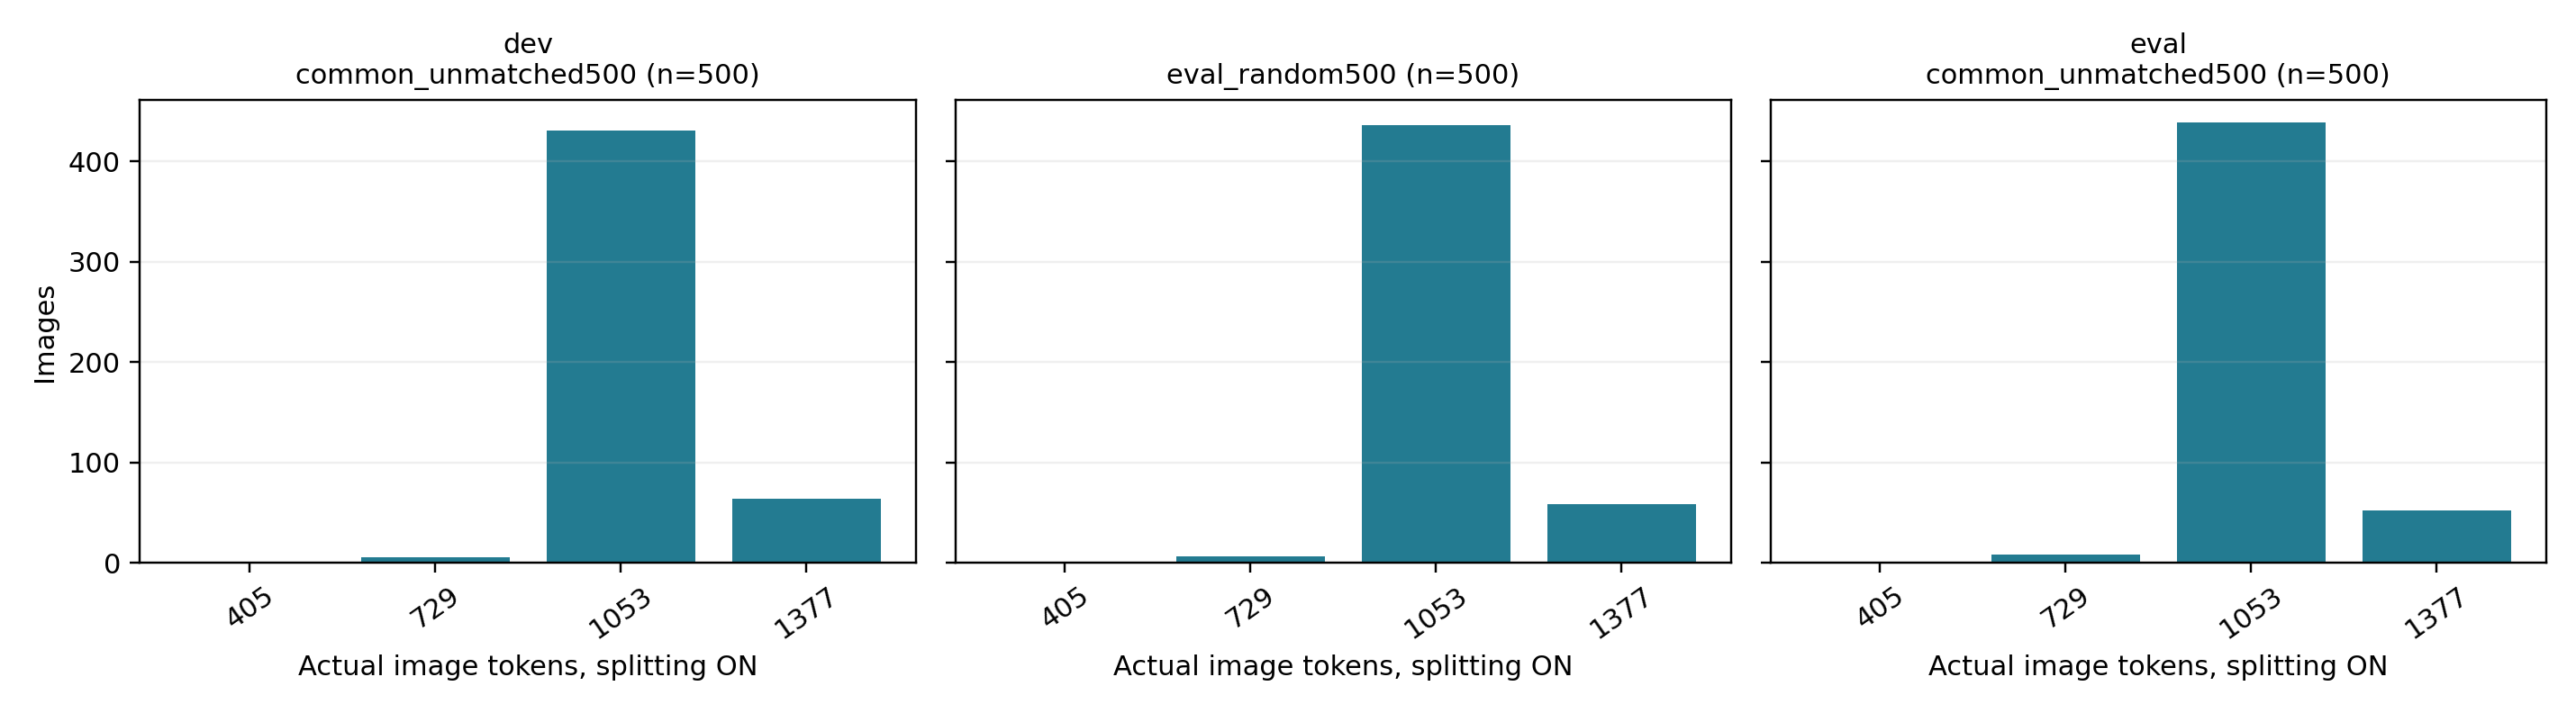

Bật chia ô giữ thêm các tile cục bộ và một ảnh global; 640×480 cho **13 × 81 = 1.053 token**, 640×640 cho **17 × 81 = 1.377 token**. Tắt chia ô cho **81 token** ở mọi ảnh trong năm manifest. Đây là số processor đo, không phải ước lượng từ pixel gốc.

### 3.2. Pad, crop, thu nhỏ và méo hình

TinyLLaVA-3.1B dùng pad vuông trước SigLIP 384px, 27×27 = **729 patch token**, không có CLS. Đã đối chiếu tensor processor Hugging Face với lớp `SigLipImageProcessor` ở mã legacy TinyLLaVA trên 20 ảnh cố định; [kết quả tương đương](eda_results/hgai/tiny_processor_equivalence.json) nêu sai lệch tối đa. Tương đương processor không chứng minh output model giống nhau khi chưa chạy forward.

SmolVLM2 **không luôn giữ nguyên tỷ lệ khung hình**: khi chia ô, processor làm tròn hai cạnh lên bội số 384 rồi tạo tile vuông; ảnh global bị resize vuông. Khi tắt chia ô, ảnh bị resize thẳng về 384×384. `do_pad=True` ở đây chủ yếu phục vụ tensor/batch, không đồng nghĩa với letterbox của TinyLLaVA. Báo độ méo tile và độ méo global riêng. Diện tích crop bằng 0 nghĩa là hợp mọi tile còn phủ ảnh, không phải từng tile nhìn thấy toàn ảnh.


### Hình học processor trên từng dev/eval

In [8]:
render_csv('eda_results/hgai/processor_geometry_summary.csv', ['partition', 'model', 'mode', 'n', 'mean_padding_pct', 'crop_area_lost_pct', 'median_distortion', 'max_distortion', 'median_global_distortion', 'median_local_source_per_pixel'])

partition,model,mode,n,mean_padding_pct,crop_area_lost_pct,median_distortion,max_distortion,median_global_distortion,median_local_source_per_pixel
dev500,SmolVLM2-2.2B,split_off,500,0.000,0,1.434,2.991,1.434,—
dev500,SmolVLM2-2.2B,split_on,500,0.000,0,1.121,1.495,1.434,0.417
dev500,TinyLLaVA-3.1B,pad_384,500,28.159,0,1.000,1.000,1.000,—
dev_common_unmatched500,SmolVLM2-2.2B,split_off,500,0.000,0,1.337,3.536,1.337,—
dev_common_unmatched500,SmolVLM2-2.2B,split_on,500,0.000,0,1.084,1.768,1.337,0.417
dev_common_unmatched500,TinyLLaVA-3.1B,pad_384,500,27.655,0,1.000,1.000,1.000,—
eval_common_unmatched500,SmolVLM2-2.2B,split_off,500,0.000,0,1.397,4.025,1.397,—
eval_common_unmatched500,SmolVLM2-2.2B,split_on,500,0.000,0,1.116,1.479,1.397,0.417
eval_common_unmatched500,TinyLLaVA-3.1B,pad_384,500,28.796,0,1.000,1.000,1.000,—
eval_random500,SmolVLM2-2.2B,split_off,500,0.000,0,1.400,2.379,1.400,—


Hệ số méo = tỷ số giữa hệ số scale hai trục, lấy giá trị ≥1; 1 là giữ tỷ lệ. Tỷ số pixel nguồn/pixel mô hình >1 là thu nhỏ và <1 là phóng lớn. Với SmolVLM2, tỷ số cục bộ dùng canvas tile còn tỷ số global dùng 384px; không đồng nhất ngân sách tile với độ thu nhỏ toàn ảnh.

`crop_area_lost_pct` đo phép crop của processor. Với đầu vào 384px, patch convolution 14px ở mode valid có 27 patch mỗi trục, phủ 378px; 6px cuối bên phải/dưới không thuộc patch (khoảng 3,10% diện tích tensor danh nghĩa). Vì vậy “processor không crop” không đồng nghĩa encoder sử dụng mọi pixel; không cộng tỷ lệ này như một phép center crop trên ảnh nguồn.

Đã bổ sung đối chứng hình học **toàn bộ val** ở TinyLLaVA 384px (pad, center crop, resize vuông) và LLaVA 336px (crop theo mã HGAI, pad). Đây là phép tính hình học trên kích thước đã áp EXIF, không phải chạy processor/model trên toàn val.


### Đối chứng hình học toàn val, phân biệt cấu hình thật và control

In [9]:
render_csv('eda_results/hgai/fixed_mode_geometry_summary.csv', None)

dataset,model,mode,images,median_pad_pct,median_crop_pct,median_distortion,median_long_edge_source_per_target
COCO,LLaVA-1.5-7B,hgai_center_crop,40504,0.000,26.719,1.000,1.905
COCO,LLaVA-1.5-7B,pad_control,40504,26.719,0.000,1.000,1.905
COCO,TinyLLaVA-3.1B,center_crop_control,40504,0.000,26.719,1.000,1.667
COCO,TinyLLaVA-3.1B,direct_square_control,40504,0.000,0.000,1.365,1.667
COCO,TinyLLaVA-3.1B,pad,40504,26.719,0.000,1.000,1.667
VizWiz,LLaVA-1.5-7B,hgai_center_crop,7750,0.000,25.000,1.000,3.857
VizWiz,LLaVA-1.5-7B,pad_control,7750,25.000,0.000,1.000,3.857
VizWiz,TinyLLaVA-3.1B,center_crop_control,7750,0.000,25.000,1.000,3.375
VizWiz,TinyLLaVA-3.1B,direct_square_control,7750,0.000,0.000,1.333,3.375
VizWiz,TinyLLaVA-3.1B,pad,7750,25.000,0.000,1.000,3.375


### 3.3. Lệch tâm vật thể đã được đo

Với bbox COCO, độ lệch tâm = khoảng cách Euclid từ tâm bbox đến tâm ảnh / nửa đường chéo ảnh. Tính cho từng instance và xuất theo ảnh: trung bình các bbox, bbox có diện tích annotation lớn nhất và trung bình có trọng số diện tích. Crowd được giữ và có số đếm riêng; không có bbox thì để trống, không gán lệch tâm 0.

Trên **40,137 ảnh có instance**, độ lệch tâm object lớn nhất có p50/p90/p95/p99 = **0.244/0.539/0.618/0.743**; 367 ảnh không có instance. [Bảng từng ảnh](eda_results/hgai/coco_object_centering.csv). VizWiz chưa có bbox ground truth, nên không có phép đo lệch tâm vật thể tương đương. Pilot chưa đủ để kiểm định tương quan lỗi CHAIR/POPE với lệch tâm.

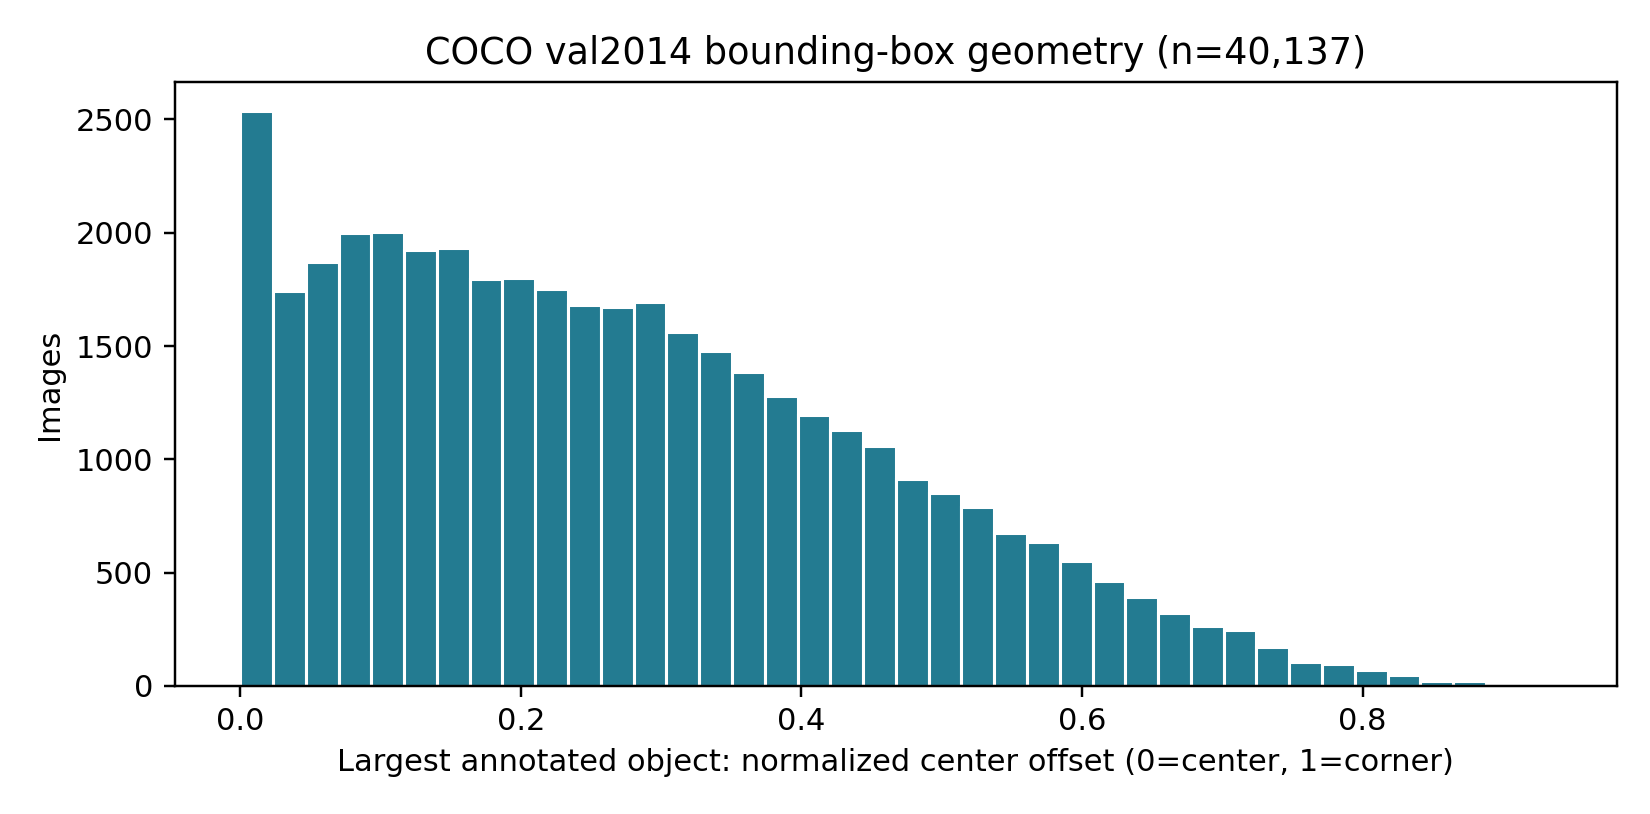

## 4. Tokenizer, đối tượng và nhãn CHAIR

Đếm caption bằng **tokenizer đúng checkpoint**, `add_special_tokens=False`, không truncation, một caption hợp lệ có annotation ID thấp nhất mỗi ảnh. Token prompt/template, visual token và output model không nằm trong bảng này. COCO có 40.504 caption được chọn; VizWiz ở phần bối cảnh có 7.542, loại 208 ảnh không còn caption hợp lệ.


### Độ dài caption theo tokenizer hai mô hình chính

In [10]:
render_csv('eda_results/hgai/caption_token_summary.csv', None)

dataset,model,n,mean,min,p50,p90,p95,p99,max
COCO,SmolVLM2-2.2B,40504,11.947,7.000,11.000,15.000,17.000,21.000,53.000
COCO,TinyLLaVA-3.1B,40504,11.982,7.000,12.000,15.000,17.000,21.000,52.000
VizWiz-context,SmolVLM2-2.2B,7542,13.472,7.000,12.000,19.000,22.000,32.000,80.000
VizWiz-context,TinyLLaVA-3.1B,7542,13.358,7.000,12.000,18.000,22.000,31.000,76.000


12 siêu danh mục COCO được đặt ngay **dưới đoạn giới thiệu này**, theo số object instance; không trộn đơn vị này với tần suất nhắc object trong caption.


### 12 siêu danh mục COCO val2014

In [11]:
render_csv('eda_results/hgai/coco_supercategories.csv', None)

Supercategory,Count,Percentage
person,88153,30.200
vehicle,32574,11.160
kitchen,29445,10.090
furniture,26296,9.010
animal,21806,7.470
food,21423,7.340
sports,16786,5.750
indoor,15795,5.410
accessory,15483,5.300
electronic,9822,3.370


### 4.1. Một định nghĩa nhóm từ chỉ người

Bảng nhóm từ chỉ người và Hình 4 dùng chung **đồng nghĩa CHAIR, ưu tiên cụm dài**, cùng caption đã chọn, không lọc POS riêng. Bảng cũ dùng năm danh từ hẹp đã được thay và mã tạo bảng cũng cập nhật để chạy lại không sinh số cũ. `person` trong annotation chiếm 30,20% số instance là một đại lượng khác.


### Nhóm người thống nhất với ontology CHAIR

In [12]:
render_csv('eda_results/tables/person_reference_one_caption_per_image.csv', ['Dataset', 'All Images', 'Selected Captions', 'Person-family Mentions', 'Selected Captions with Person Family', 'Selected Captions with Person Family (%)', 'Matching Rule'])

Dataset,All Images,Selected Captions,Person-family Mentions,Selected Captions with Person Family,Selected Captions with Person Family (%),Matching Rule
MS-COCO val2014,40504,40504,16557,15196,37.520,"CHAIR person synonyms; longest phrase first; lexical, no POS filter"
VizWiz val,7750,7542,678,653,8.660,"CHAIR person synonyms; longest phrase first; lexical, no POS filter"


### 4.2. Không dùng caption đơn làm ground truth

CHAIR chính thức dùng hợp nhãn instance và đối tượng từ mọi caption chuẩn, với quy tắc chuẩn hóa của evaluator. Đối chiếu lexical trong EDA chỉ chẩn đoán độ phủ, không thay evaluator CHAIR. Cần pin evaluator và annotation nguồn trước khi chạy baseline/HGAI, lưu numerator/denominator cho CHAIR-S và CHAIR-I, cùng recall/F1 để tránh giảm hallucination bằng cách không nhắc object.

Độ phủ lexical đã đo: một caption thu hồi **38.07%** lớp instance, hợp mọi caption thu hồi **55.26%**. [Kiểm tra độ đầy đủ nhãn](eda_results/vlm_extensions/coco_caption_label_completeness.json). Không ép mọi ảnh có đúng năm caption vì annotation COCO có số lượng caption biến thiên.

## 5. Giao thức HGAI và thiết kế thí nghiệm

### 5.1. Mốc LLaVA-1.5-7B phải chạy trước

[Mã đánh giá của tác giả](https://github.com/ZhangqiJiang07/middle_layers_indicating_hallucinations/blob/main/chair_eval.py) dùng **“Please help me describe the image in detail.”**, 500 ảnh COCO, `max_new_tokens=512`, `do_sample=False`, `num_beams=1`, HGAI mean aggregation, α=0,5, layer **5–18 inclusive**. Bản source và commit được lưu trong `eda_resources/hgai_original/`.

Bảng 2 và 3 của bài báo HGAI v3 ghi CHAIR-S greedy LLaVA **53,0 ở 512 token** và **23,8 ở 64 token**; đây là số công bố, không phải kết quả ở workspace. [Bảng 2](https://arxiv.org/html/2411.16724v3#S4.T2), [bảng 3](https://arxiv.org/html/2411.16724v3#S4.T3). Con số 20,8 trong nội dung đối chiếu người dùng gửi chưa khớp nguồn gốc; bản v1 cũng ghi 23,8. Độ dài ngắn thu hẹp phần lỗi có thể giảm (headroom), nên 64 token không còn là giao thức chính.

Mã `eval_data_loader.py` gọi processor trực tiếp; với CLIP 336px đây là resize/crop. Config checkpoint LLaVA ghi pad nhưng không tự chứng minh đường chạy đánh giá đã pad. Nhánh kiểm chứng dùng đường xử lý theo mã tác giả; pad là control riêng. EXIF vẫn áp trước mọi tiền xử lý. Cần kiểm tra equivalence native LLaVA/HF conversion khi có trọng số; chưa tuyên bố đã tái lập hàng 53,0 bằng script baseline chưa chạy.

### 5.2. Tách ảnh hưởng độ dài khỏi ảnh hưởng prompt

| Điều kiện | Prompt | Token tối đa | Vai trò |
| :--- | :--- | ---: | :--- |
| detailed512 | Prompt mô tả chi tiết HGAI | 512 | Giao thức chính |
| detailed64 | Cùng prompt chi tiết | 64 | Chỉ thay giới hạn độ dài |
| concise64 | Prompt một câu và cho phép từ chối | 64 | Điều kiện phụ thay prompt và từ chối |

Mỗi so sánh baseline–HGAI phải giữ cùng manifest, processor, template đúng mô hình, prompt, seed và decoding. Không lấy chênh lệch `detailed512`/`concise64` làm riêng hiệu ứng α. Script `llava_pilot.py` mặc định dùng dev_common_unmatched500, detailed512 và đường crop theo mã HGAI; hỗ trợ ba điều kiện và cả pad control, lưu cấu hình và SHA manifest, từ chối ghi đè output đã có. Script chỉ chạy baseline LLaVA; không tự nhận là adapter HGAI cho Phi-2/SmolLM2.

### 5.3. Layer và α của VLM nhỏ

Tuning dùng **dev_common_unmatched500**, không dùng eval hoặc POPE để chọn thông số. Dải layer gốc chỉ là mốc LLaVA; kiểm tra dải theo tỷ lệ chiều sâu của từng LLM, rồi hiệu chỉnh từ đo attention/ablation trên dev. Grid đề xuất ban đầu: [10%,40%], [15%,60%], [25%,70%] chiều sâu; α ∈ {0; 0,25; 0,5; 0,75; 1}. Đây là kế hoạch, chưa phải dải layer hay α đã được thực nghiệm chọn.

HGAI gốc cộng α × trung bình liên head của trị tuyệt đối attention **logit** vào các vị trí ảnh trước softmax. Không thay công thức thành α nhân số token. Số vị trí ảnh thay đổi sẽ làm thay đổi số phần tử bị can thiệp và phép chuẩn hóa softmax; vì vậy phải báo kết quả theo phân bố token và có split_on/off ablation. Nhận diện đúng các vị trí `<image>` của SmolVLM2 sau processor; loại token grid/biên. Không hard-code một dải liên tục 576 token cho SmolVLM2, hoặc dùng số head/query-head của LLaVA cho mô hình có GQA. Phi-2 có cấu trúc attention khác; adapter cần kiểm tra α=0 khớp baseline, KV-cache, mask và generation từng bước trước đo điểm.

CHAIR-S/I cần đi cùng object recall/F1, số output token thật, tỷ lệ chạm giới hạn, tỷ lệ từ chối, repetition/Distinct-1, thời gian và bộ nhớ. Ước lượng CI bằng bootstrap **ghép cặp theo ảnh** cho baseline–HGAI; giữ toàn bộ lỗi trên cùng ảnh trong một mẫu bootstrap. Chọn thông số xong phải lưu cấu hình rồi mới chạy eval.

### 5.4. POPE là benchmark kiểm tra chéo riêng

Dùng các bộ COCO random/popular/adversarial chính thức, giữ nhãn và negative sampling gốc. Không coi 500 ảnh CHAIR là một POPE mới hoặc ép POPE trùng manifest rồi so với số công bố. Báo accuracy, precision, recall, F1 và yes-rate, kèm số câu hỏi/ảnh, nguồn và hash. Nếu phân tích thêm các ảnh giao với eval500 thì ghi rõ đó là subset, không thay điểm POPE chính thức.

[Cấu hình thí nghiệm máy đọc được](eda_results/hgai/experiment_config.json) cố định các điều kiện trên. Adapter HGAI đã triển khai, kiểm tra công thức, GQA, mask/cache và α=0 trên CPU, rồi chạy với trọng số Smol thật. Chiến dịch tuning/dev500, khóa lựa chọn trước eval, đối chứng và POPE đã có mã thực thi; đánh giá đầy đủ ba VLM đang chờ hoàn tất. [Hướng dẫn thực thi](HGAI_Experiments.md).

## 6. Trạng thái và tái lập

Đã có năm manifest cố định, **7.500 dòng processor**, token caption của cả hai mô hình, hình học toàn val/COCO bbox, đối chiếu nguồn và rà EXIF. Trọng số **SmolVLM2 chính thức đã được tải và xác minh SHA-256**, tổng 8.987.224.056 byte; [provenance trọng số](eda_results/hgai/smol_weights_provenance.json). Không còn dùng “thiếu trọng số” làm lý do cho SmolVLM2.

Máy hiện tại có RTX 3050 Laptop 4 GB; runner `smol_baseline.py` dùng NF4, greedy, template của processor chính thức và bật chia ô. Caption dùng prompt chi tiết, giới hạn 512 token. CHAIR dùng mã evaluator gốc đã pin, chỉ chuyển cú pháp print Python 2 và IO JSONL/val2014; vẫn giữ tokenizer NLTK, singularize Pattern, synonym và các quy tắc cụm từ. POPE giữ parser yes/no trong evaluator chính thức. Nguồn và revision nằm trong [provenance evaluator](eda_results/hgai/metrics_provenance.json).

**Pilot không thay đánh giá đầy đủ:** caption pilot là prefix 20 ảnh của dev mới, không phải mẫu eval500. POPE pilot giữ prefix câu hỏi theo thứ tự gốc, không phải đủ 3.000 câu mỗi biến thể. Không dùng các điểm pilot để kết luận hiệu quả HGAI hoặc so trực tiếp với hàng LLaVA 53,0; NF4 cũng là một điều kiện precision riêng. Chưa có α được chọn từ dev500 hoàn chỉnh hoặc benchmark/đối chứng đầy đủ ba VLM.

**Trạng thái triển khai:** `vlm_experiment.py` hỗ trợ cả ba mô hình, ba điều kiện prompt, CHAIR/POPE, baseline/HGAI và resume với cấu hình/hash cố định; `score_vlm_runs.py` dùng chung schema, guard từ chối/output trống/lặp, Distinct-1 và CI ghép cặp theo ảnh. CI POPE gom toàn bộ câu hỏi của cùng ảnh trong một mẫu bootstrap. TinyLLaVA giữ 26 layer SigLIP thực tế theo mã legacy; cả 877 tên tensor khớp index checkpoint. Trạng thái tải/chạy Tiny/LLaVA được đối chiếu với output thật trong snapshot; không khẳng định equivalence native/HF đã đạt. [Kiểm chứng adapter](eda_results/hgai/hgai_adapter_validation.json), [kiểm chứng scorer](eda_results/hgai/hgai_scoring_validation.json), [rà soát tổng quan](EDA_HGAI_Review.md).

**Kiểm chứng Smol thật trên hai ảnh dev:** α=0 cho caption và số token khớp baseline native; α=0,5 thực thi can thiệp nhưng độ dài trung bình giảm từ **298 xuống 10,5 token**, object F1 giảm về 0 và CHAIR-I trở thành không xác định vì không có object được nhận diện. Đây là kiểm tra đường chạy, không phải bằng chứng cải thiện HGAI. Guard chọn cấu hình yêu cầu recall/F1 không giảm quá 0,02, độ dài còn ít nhất 50% baseline; refusal/output trống/truncation/lặp không tăng quá 0,05. Các ngưỡng được khóa trước lượt tuning dev500 đầy đủ. [Kiểm chứng trọng số thật](eda_results/hgai/hgai_smol_real_weight_validation.json).

`run_hgai_suite.py` chạy tuần tự dev500 baseline + 12 cấu hình can thiệp mỗi mô hình; lưu selection trước eval500 và POPE 3×3.000 câu/điều kiện. Có hai control prompt cho cả Smol/Tiny, split_off cho Smol và pad/crop cho LLaVA. GPU 4 GB dùng NF4/offload; cả chiến dịch có thể kéo dài nhiều ngày. Bảng tiến độ dưới đây là ảnh chụp tại thời điểm dựng báo cáo, không phải trạng thái trực tiếp; output chưa đủ dòng không có điểm. [Thời điểm và trạng thái chiến dịch](eda_results/hgai/experiment_run_status.json).



### Pilot SmolVLM2 NF4 — kiểm tra pipeline, không phải điểm benchmark đầy đủ

In [13]:
render_csv('eda_results/hgai/baseline_pilot_summary.csv', None)

task,partition,model_precision,role,images,questions,CHAIR_S_pct,CHAIR_I_pct,accuracy_pct,precision_pct,recall_pct,F1_pct,yes_rate_pct
chair,dev_common_unmatched500,nf4,feasibility_pilot,20,—,35.000,9.294,—,—,—,—,—
pope,official-pope-adversarial,nf4,feasibility_pilot,10,60.000,—,—,70.000,63.636,93.333,75.676,73.333
pope,official-pope-popular,nf4,feasibility_pilot,10,60.000,—,—,76.667,70.000,93.333,80.000,66.667
pope,official-pope-random,nf4,feasibility_pilot,10,60.000,—,—,90.000,87.500,93.333,90.323,53.333


### Tiến độ thực tế — tách pilot khỏi benchmark đầy đủ

In [14]:
render_csv('eda_results/hgai/experiment_run_status.csv', ['model_key', 'task', 'partition', 'alpha', 'precision', 'generated_rows', 'requested_rows', 'status', 'role', 'CHAIR_S_pct', 'CHAIR_I_pct', 'accuracy'])

model_key,task,partition,alpha,precision,generated_rows,requested_rows,status,role,CHAIR_S_pct,CHAIR_I_pct,accuracy
smol,chair,dev_common_unmatched500,0.500,nf4,2,2,scored,feasibility_pilot,0.000,—,—
smol,chair,dev_common_unmatched500,0.000,nf4,2,2,scored,feasibility_pilot,0.000,0.000,—
smol,chair,eval_common_unmatched500,0.000,nf4,65,500,partial,baseline,—,—,—
smol,chair,dev_common_unmatched500,0.000,nf4,20,20,scored,feasibility_pilot,35.000,9.294,—
smol,pope,official-pope-adversarial,0.000,nf4,60,60,scored,feasibility_pilot,—,—,0.700
smol,pope,official-pope-popular,0.000,nf4,60,60,scored,feasibility_pilot,—,—,0.767
smol,pope,official-pope-random,0.000,nf4,60,60,scored,feasibility_pilot,—,—,0.900
smol,chair,dev_common_unmatched500,0.000,nf4,1,1,scored,feasibility_pilot,0.000,0.000,—


Chạy phần CPU mới bằng môi trường riêng; không thay môi trường cũ dùng CLIP:

```powershell
# Dùng Python 3.10–3.12; CHAIR legacy cần lib2to3.
python -m venv --system-site-packages .venv-eda
.venv-eda/Scripts/python.exe -m pip install -r requirements-hgai-cpu.txt
python fetch_hgai_assets.py
python fetch_training_metadata.py
python fetch_onevision_ids.py
.venv-eda/Scripts/python.exe hgai_cpu_audit.py --prepare-only
.venv-eda/Scripts/python.exe small_vlm_training_overlap.py
.venv-eda/Scripts/python.exe lock_common_unmatched.py
.venv-eda/Scripts/python.exe small_vlm_training_overlap.py
.venv-eda/Scripts/python.exe hgai_cpu_audit.py --missing-only
.venv-eda/Scripts/python.exe verify_tiny_processor.py
.venv-eda/Scripts/python.exe sampling_fix_diagnostics.py
python caption_sampling_sensitivity.py
python vizwiz_rotation_review.py
.venv-eda/Scripts/python.exe rebuild_hgai.py
```

Các fetch EDA chỉ tải asset CPU/annotation/ID; `fetch_smol_baseline.py` là bước riêng tải trọng số chính thức. Trọng số, tokenizer, annotation lớn và môi trường Python bị `.gitignore` bỏ qua. Năm manifest cùng khóa, CSV/hình và output pilot được lưu trong workspace.

Chạy lại pilot hoặc mở rộng baseline bằng runner có kiểm tra khóa và từ chối ghi đè:

```powershell
.venv-eda/Scripts/python.exe -m pip install -r requirements-hgai-inference.txt
.venv-eda/Scripts/python.exe fetch_smol_baseline.py
.venv-eda/Scripts/python.exe fetch_hgai_metrics.py
.venv-eda/Scripts/python.exe smol_baseline.py --partition dev_common_unmatched500 --limit 20
.venv-eda/Scripts/python.exe score_hgai_baseline.py experiment_outputs/smol_baseline/chair_dev_common_unmatched500_nf4_split_on_n20.jsonl
```

Để chạy đủ 500 ảnh, dùng `--partition eval_common_unmatched500 --limit 500`; đây là baseline NF4 trên nhánh lọc, không phải tái lập FP16 của bài báo. POPE dùng `--task pope --pope-variant random --limit 3000`, lặp lại cho popular/adversarial. Chấm từng JSONL bằng `score_hgai_baseline.py`; `--resume` chỉ tiếp tục khi config/hash trùng, không mở rộng limit trong một file pilot đã khóa. [Mã runner](smol_baseline.py), [mã chấm điểm](score_hgai_baseline.py).

## Phụ lục A. VizWiz: bối cảnh và kiểm tra EXIF

VizWiz không nằm trong benchmark HGAI chính hiện tại. Vai trò của nó là minh họa domain gap/giới hạn ontology: 7.750 ảnh val; 99,23% ảnh dọc sau EXIF; 64,75% có chữ theo đa số annotator; 9,69% có ≥3/5 caption từ chối. Median Laplacian toàn val sau resize cạnh ngắn 480px là 152,16, so với 1.140,08 ở COCO; đây là năng lượng biên/texture, không tự chứng minh nguyên nhân blur hay hiệu quả HGAI.

Có 493 ảnh có EXIF xoay, 845 ảnh có nhãn Rotated đa số, giao 199. Nhóm **646/7.750 (8,335%)** có nhãn Rotated nhưng không có thẻ EXIF xoay: EXIF không biến đổi pixel nhóm này. Đây là nhóm nguy cơ còn lại, **không phải số ảnh lỗi sau EXIF đã được gán nhãn lại**; không suy rằng toàn bộ 199 ảnh giao đã được sửa hoàn toàn.

Đã xem 40 cặp raw/sau EXIF, seed42, 20 ảnh ở mỗi nhóm. Một reviewer là trợ lý đã ghi từng ảnh và giữ trường hợp không rõ. Nhóm có EXIF: 17 ảnh hướng upright, 1 upright nhưng còn tilt, 2 chưa đủ chắc hướng; nhóm không EXIF: 18 sideways/upside-down, 1 nhãn vật thể quay ngang, 1 upright nhưng có tilt. Mẫu có phân tầng theo filename/ID và có thể chứa ảnh trùng byte, chỉ dùng kiểm tra pipeline; không ngoại suy thành tỷ lệ lỗi toàn bộ 199 hoặc 646 ảnh. [Worklist đã rà](eda_results/hgai/vizwiz_rotation_review40.csv), [thiết kế lấy mẫu](eda_results/hgai/vizwiz_rotation_review_sampling.json) và bốn contact sheet lưu cùng thư mục. Pipeline vẫn chốt EXIF; không tự xoay thêm ảnh từ nhãn Rotated vì nhãn này không cung cấp hướng/độ xoay.

Hình 4 giữ **20 lớp** được nhắc nhiều nhất trong caption VizWiz, cùng đơn vị một caption/ảnh; bảng đủ 80 lớp nằm ở CSV. `laptop` phần lớn đến từ từ `computer` (588/879), `dining table` từ `table` (633/794). Đây là quy tắc đồng nghĩa CHAIR, không phải ground truth object của VizWiz; phần mở rộng VizWiz nếu có sau này cần nhãn object và negative probes phù hợp.

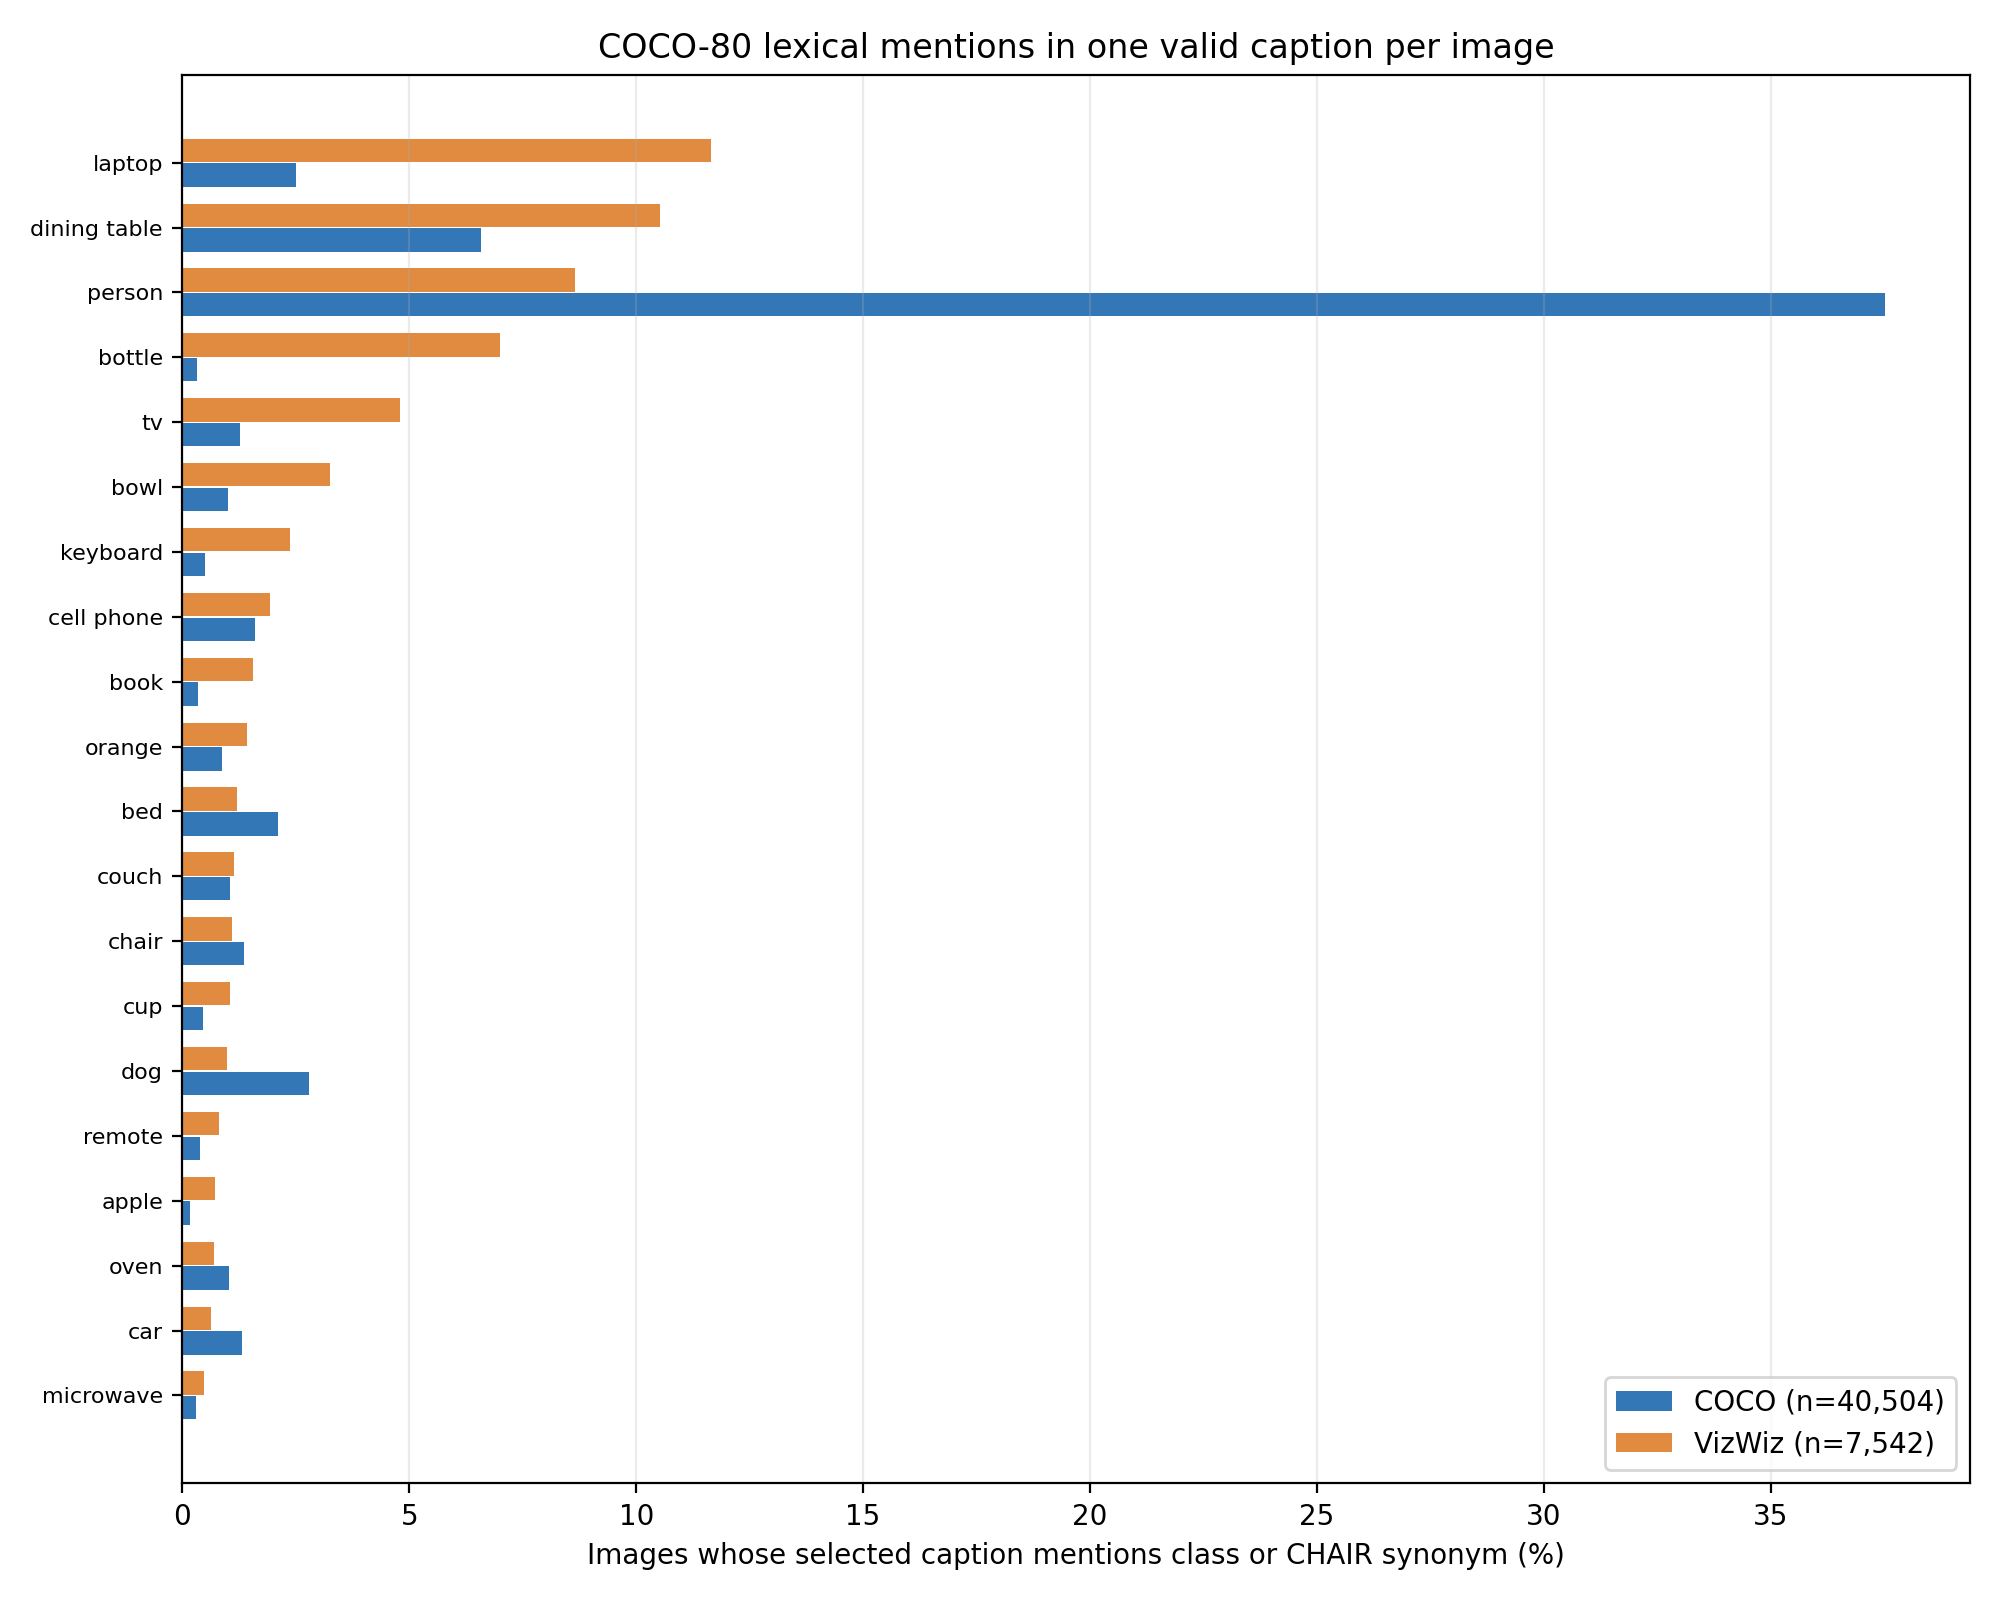

Hình 8 và 9 chỉ chèn một lần ở phụ lục, sau nội dung giải thích; notebook nhúng ảnh vào attachment để xuất độc lập.

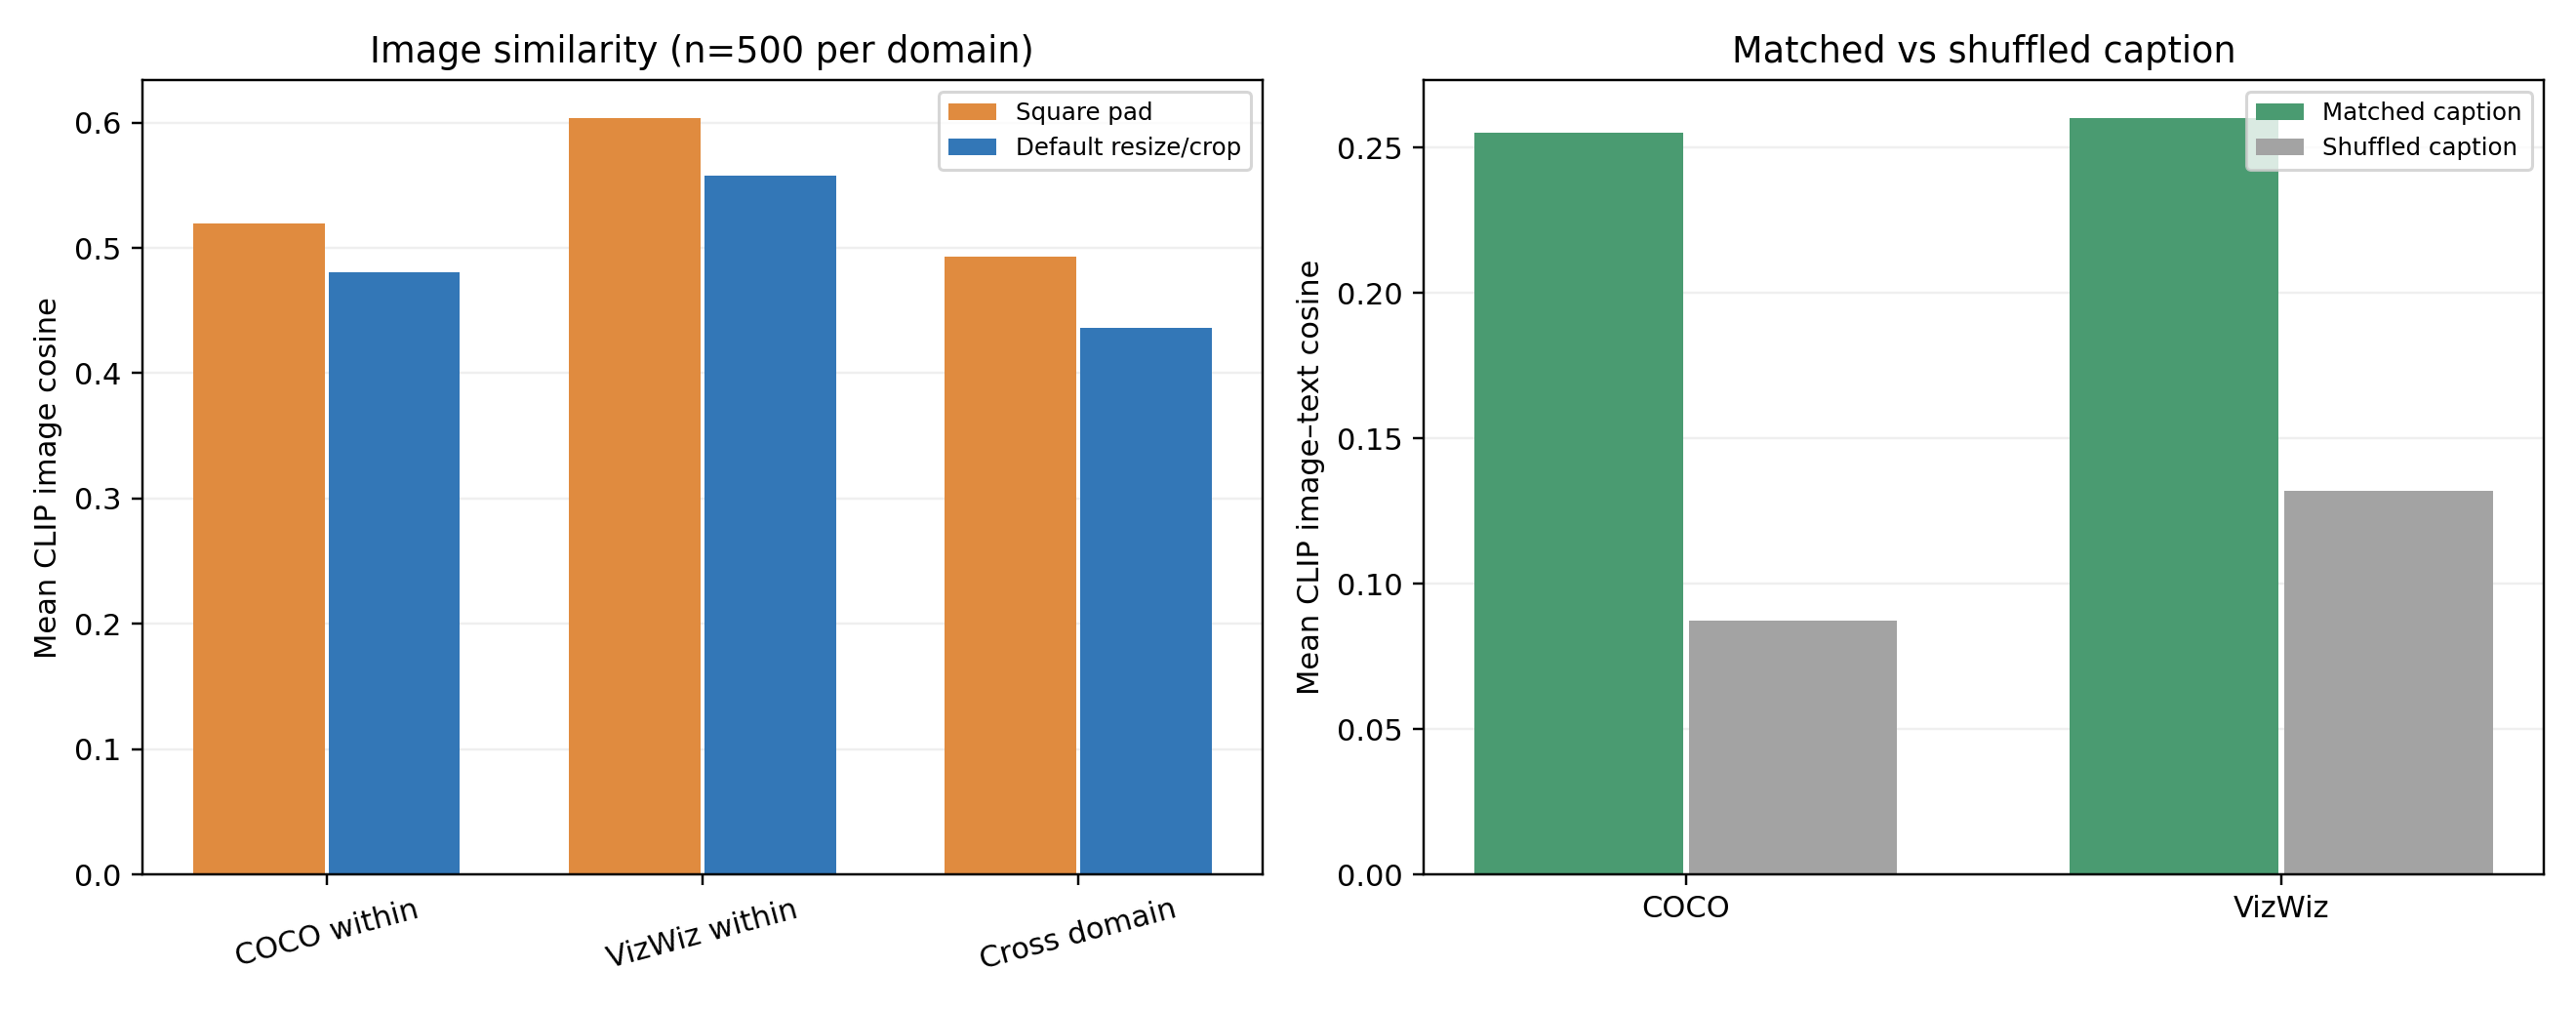

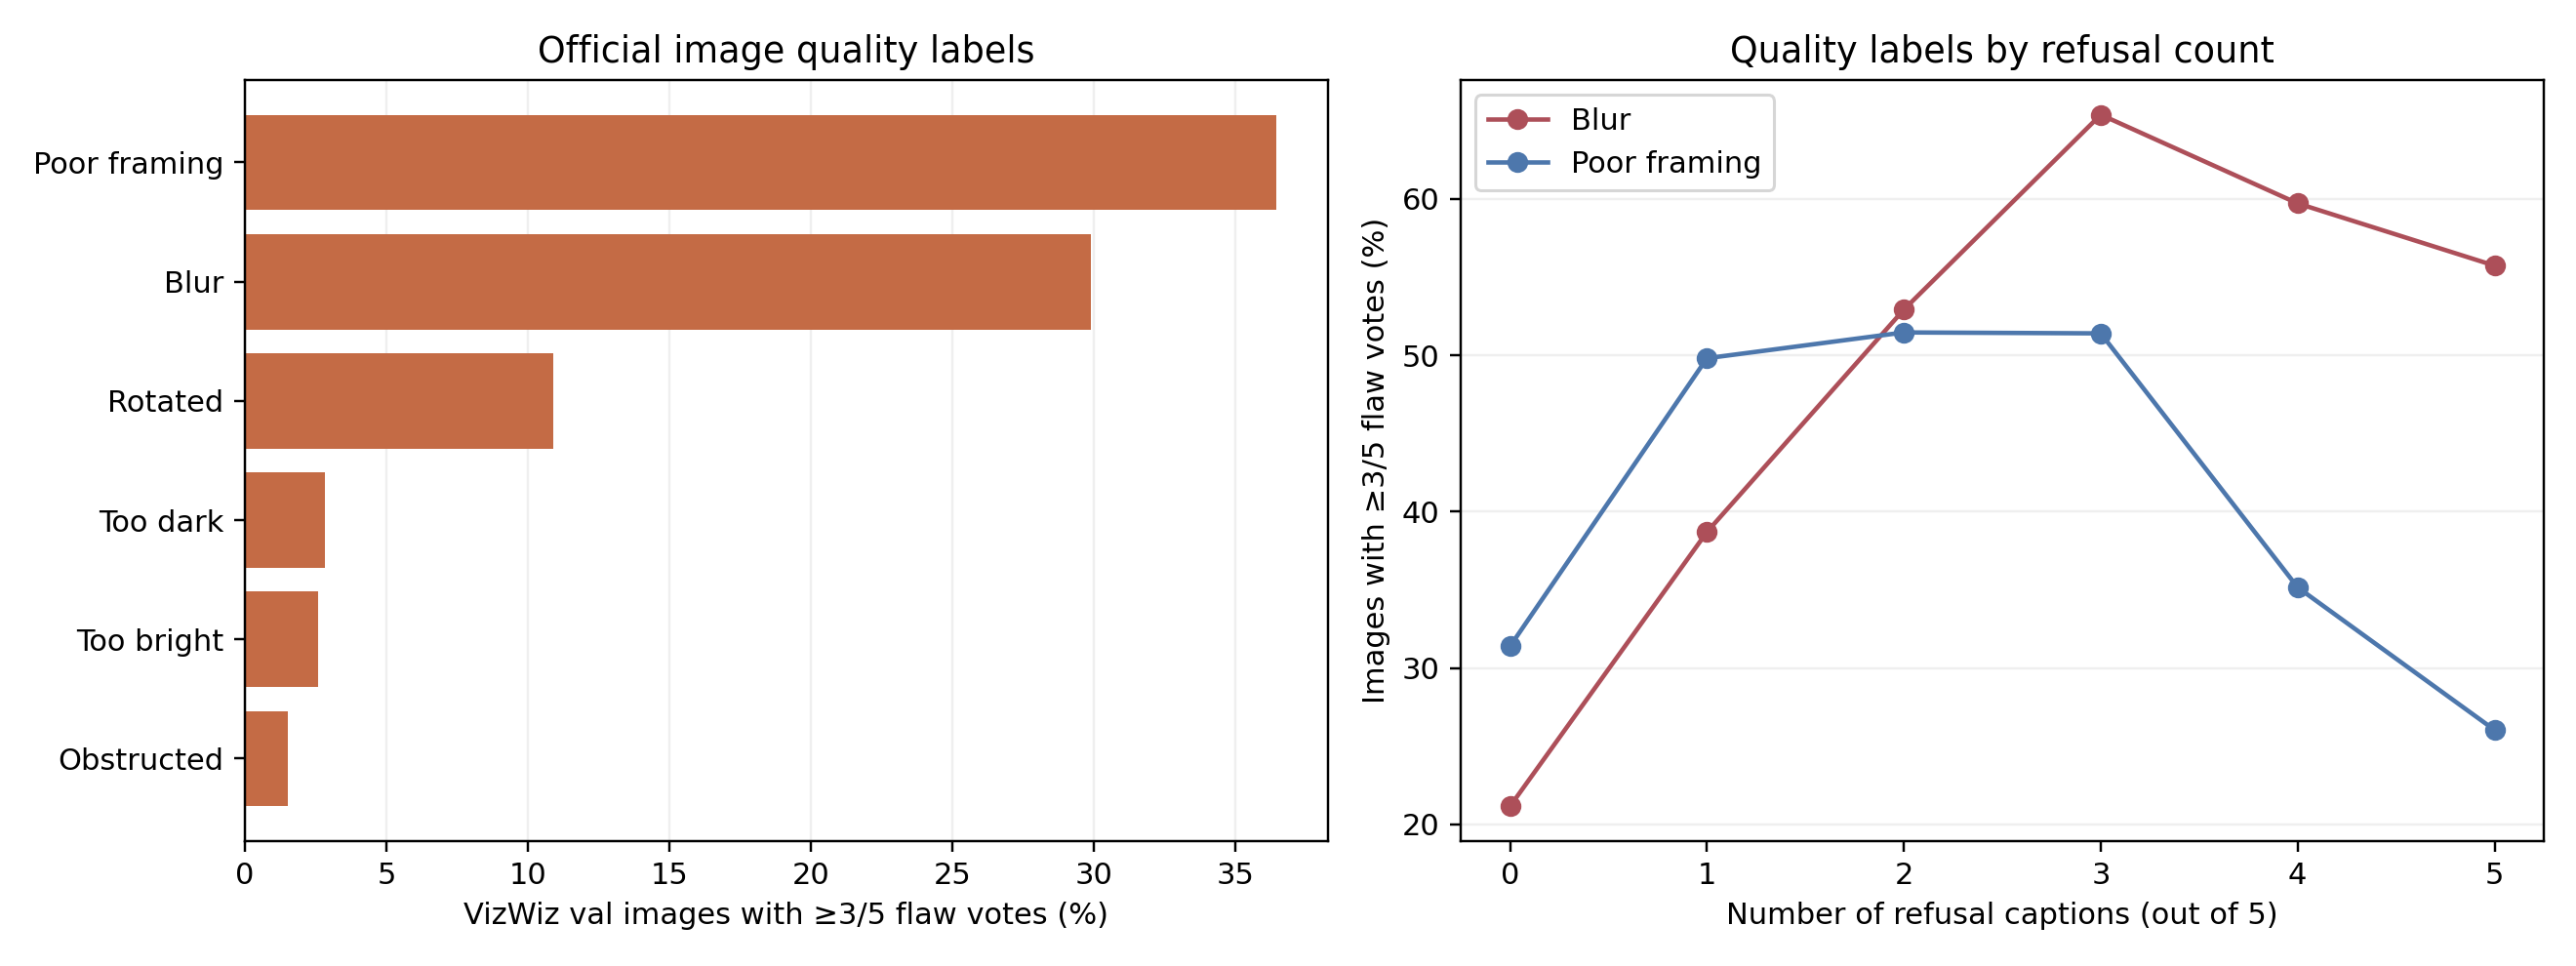

Toàn bộ phân tích COCO–VizWiz cũ được giữ ở [tài liệu bối cảnh](EDA_COCO_vs_VizWiz_Context.md) cùng các CSV/hình gốc; không còn chiếm một nửa nội dung chính hoặc quy định dev/giao thức HGAI. [Bảng từ gốc của Hình 4](eda_results/tables/coco80_source_terms.csv).

## Tài liệu nguồn

1. [HGAI: Devils in Middle Layers, bài báo](https://arxiv.org/abs/2411.16724); [mã chính thức](https://github.com/ZhangqiJiang07/middle_layers_indicating_hallucinations).
2. [SmolVLM2-2.2B-Instruct: model card, processor và dữ liệu huấn luyện](https://huggingface.co/HuggingFaceTB/SmolVLM2-2.2B-Instruct).
3. [TinyLLaVA-3.1B: checkpoint và hai recipe](https://huggingface.co/bczhou/TinyLLaVA-3.1B); [bài báo TinyLLaVA](https://arxiv.org/abs/2402.14289).
4. [ShareGPT4V annotation](https://huggingface.co/datasets/Lin-Chen/ShareGPT4V); [OneVision upstream](https://huggingface.co/datasets/lmms-lab/LLaVA-OneVision-Data).
5. [CHAIR gốc](https://aclanthology.org/D18-1437/); [POPE chính thức](https://github.com/RUCAIBox/POPE).
6. [COCO](https://cocodataset.org/); [VizWiz-QualityIssues](https://vizwiz.org/tasks-and-datasets/image-quality-issues/).